# 2 · Le modèle suit-il la cible ?

On le teste là où on connaît la vérité : **43 épisodes simulés de test** (variantes du réseau et
jours jamais vus à l'apprentissage), à chaque pas de 5 minutes.

> **En bref**
> - **Débits** : C suit la forme des vrais débits, mais avec une erreur médiane de 0,44 m³/h,
>   plus que si on recopiait le modèle calibré sans fuite (0,13 m³/h).
> - **Bilan q1 − q2** : en valeur, il ne mesure pas la fuite (vingt fois trop petit ; 6 % des fuites
>   sortent du bruit).
> - **Mais rangé**, le bilan mène à la fuite : elle est dans les 5 premières conduites **56 %** du
>   temps (hasard 21 %). La note de C fait **66 %**, celle de B 69 %.
> - Les petites fuites (< 4 m³/h) sont presque manquées (26 %).

In [1]:
import sys
sys.path.insert(0, "..")
from conduites import presentation as P

## 1. L'apprentissage

L'erreur sur les épisodes d'apprentissage et sur des épisodes de validation jamais vus.

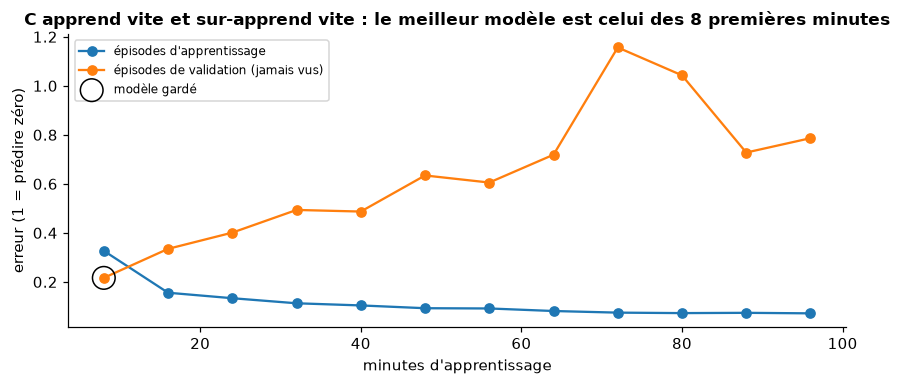

In [2]:
P.apprentissage()

L'erreur de validation remonte dès la 2e étape : au-delà, le modèle apprend par cœur les épisodes
d'apprentissage. On garde le modèle des 8 premières minutes.

## 2. La cible « débits »

Le débit de chaque moitié de conduite, prédit contre le vrai. Point de comparaison : recopier les
débits du modèle calibré sans fuite, que le modèle reçoit en entrée.

modèle calibré sans fuite (recopié)    0.132
C                                      0.438
Name: erreur médiane (m³/h), dtype: float64

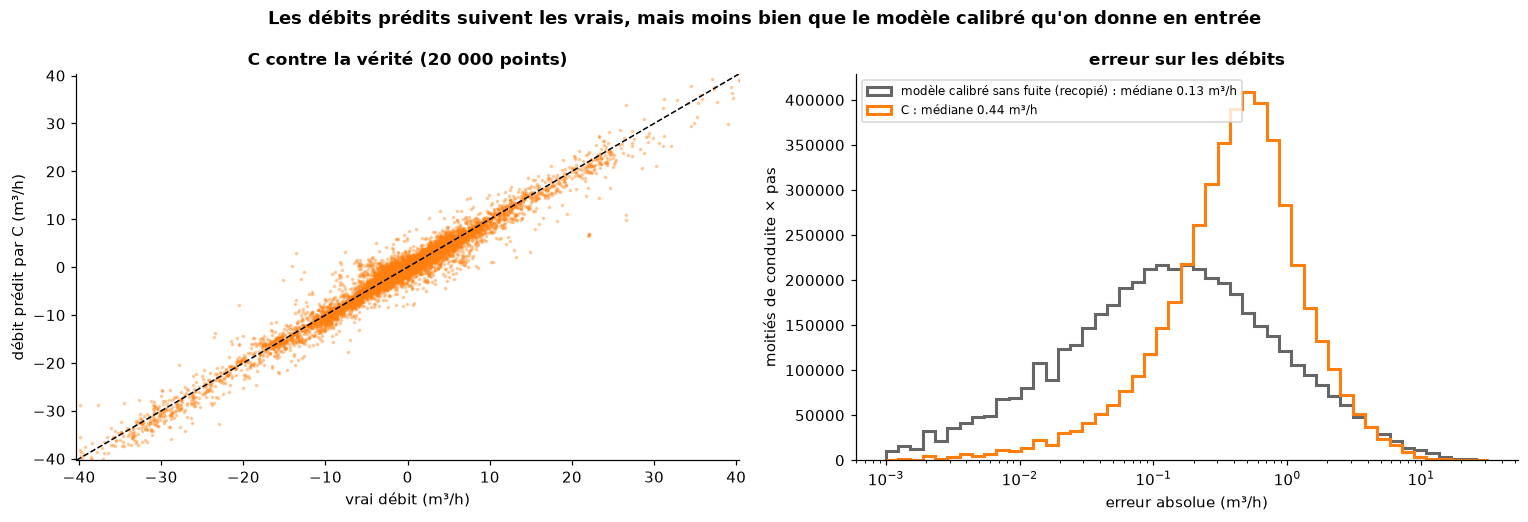

In [3]:
P.debits_contre_verite()

La forme est là (les points suivent la diagonale), mais C fait **trois fois plus d'erreur** que la
simple recopie du modèle calibré. Il n'a pas appris de débits meilleurs que ceux qu'on lui donne.

Le bilan q1 − q2 sur les conduites qui fuient, contre la vraie fuite :

,fuites dont le bilan sort du bruit,pente (1 = parfait)
C,0.06,0.052


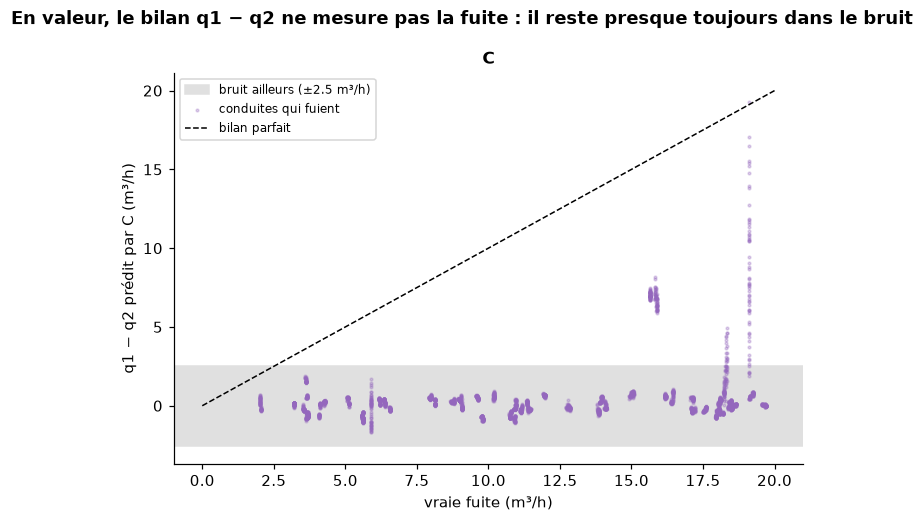

In [4]:
P.bilan_contre_fuite()

## 3. La cible « où est la fuite »

On range les conduites par la carte (la note, ou le bilan q1 − q2) et on regarde à quelle place
arrive la vraie fuite, **à 300 m près** (la tolérance de BattLeDIM). « Top-5 » = la fuite est
trouvée en vérifiant les 5 premières conduites.

,C · note,C · bilan,B · note,hasard
top-1,0.44,0.24,0.45,0.04
top-5,0.66,0.56,0.69,0.21
top-10,0.73,0.70,0.79,0.38


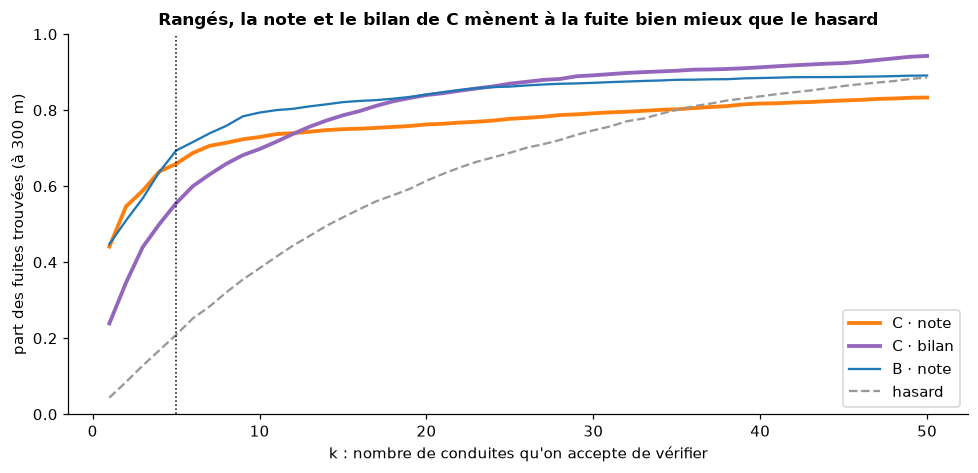

In [5]:
P.top_k()

Rangées, les deux cartes de C trouvent la fuite bien plus souvent que le hasard. Le bilan démarre
moins bien (24 % en tête contre 44 % pour la note) mais rattrape la note au-delà de 12 conduites
vérifiées. B, sans débits, fait comme la note de C.

La même mesure (top-5), selon la taille de la fuite :

,C · note,C · bilan,B · note,hasard
< 4,0.26,0.27,0.37,0.19
4–7,0.39,0.51,0.51,0.22
7–10,0.67,0.54,0.81,0.20
10–15,0.72,0.37,0.70,0.21
15–20,0.87,0.80,0.83,0.21


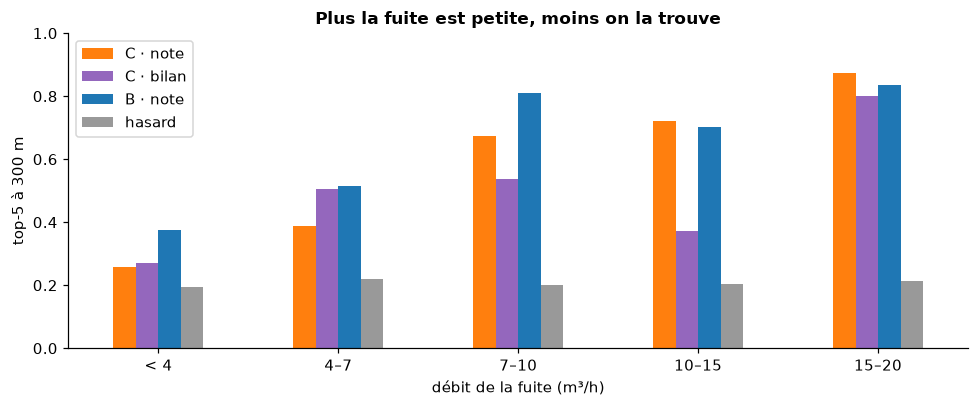

In [6]:
P.par_taille()

Sous 4 m³/h, aucune carte ne fait vraiment mieux que le hasard. Au-dessus de 15 m³/h, la fuite est
trouvée 80 à 87 % du temps.

**Suite** : carnet 3, les cartes, 2018 et les limites.